<a href="https://colab.research.google.com/github/Yubraj45/CIFAR100/blob/main/CIFAR100.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## CIFAR-100 Classification with Deep Transfer Learning

This repository contains a PyTorch implementation for classifying the CIFAR-100 dataset using a fine-tuned pre-trained ResNet-50 backbone. Through the use of advanced data augmentation, high-resolution input resizing ($224 \times 224$), and regularizations like Label Smoothing, the model achieves a high classification accuracy on the CIFAR-100 dataset.

### Project Highlights
- **Model Architecture**: Pre-trained ResNet-50 adapted for 100 classes.
- **Optimizations**: Cosine Annealing Learning Rate scheduling & Label Smoothing Cross-Entropy Loss.
- **Performance**: Peak Validation Accuracy of **84.95%**.
- **Export**: PyTorch weight dictionary saved directly to `/content/models/cifar100_resnet50.pth`.

In [1]:
from datasets import load_dataset

ds = load_dataset("uoft-cs/cifar100")

README.md:   0%|          | 0.00/9.98k [00:00<?, ?B/s]

cifar100/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  119MB            

cifar100/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

cifar100/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 23.8MB            

cifar100/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/10000 [00:00<?, ? examples/s]

In [2]:
#device agnostic code
import torch
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cuda'

In [3]:
train_dataset = ds['train']
test_dataset = ds['test']

In [4]:
train_dataset

Dataset({
    features: ['img', 'fine_label', 'coarse_label'],
    num_rows: 50000
})

In [5]:
image = train_dataset[0]['img']
label = train_dataset[0]['fine_label']
coarse_label = train_dataset[0]['coarse_label']

print(image)
print(label)
print(coarse_label)

<PIL.PngImagePlugin.PngImageFile image mode=RGB size=32x32 at 0x7A5F3416E510>
19
11


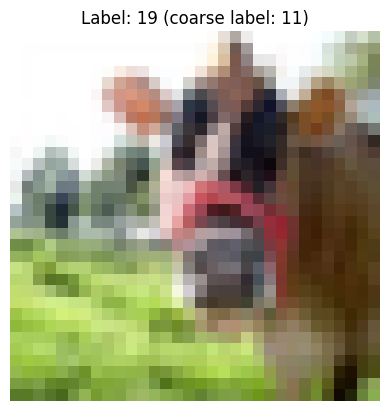

In [6]:
import matplotlib.pyplot as plt
plt.imshow(image)
plt.title(f"Label: {label} (coarse label: {coarse_label})")
plt.axis('off')
plt.show()

In [7]:
from torchvision import transforms

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=(0.5071, 0.4867, 0.4408),
                         std=(0.2675, 0.2565, 0.2761))
])

In [8]:
def transform_batch(batch):
    batch['img'] = [transform(img) for img in batch['img']]
    batch['label'] = batch['fine_label']
    return batch

dataset = ds.with_transform(transform_batch)

In [9]:

test_sample = dataset['train'][0]
print("Image shape:", test_sample['img'].shape)
print("Label:", test_sample['label'])

Image shape: torch.Size([3, 32, 32])
Label: 19


In [10]:
train_dataset = dataset['train']
test_dataset = dataset['test']

In [11]:
print(f"Transformed Training Set Size: {len(train_dataset)}")
print(f"Transformed Test Set Size: {len(test_dataset)}")

# Quick validation of a test set sample
test_sample = test_dataset[0]
print("Sample test image shape:", test_sample['img'].shape)
print("Sample test label:", test_sample['label'])

Transformed Training Set Size: 50000
Transformed Test Set Size: 10000
Sample test image shape: torch.Size([3, 32, 32])
Sample test label: 49


In [12]:
# Split train_dataset into train and validation sets (90% train, 10% val)
split_result = dataset['train'].train_test_split(test_size=0.1, seed=42, stratify_by_column="fine_label")

train_dataset = split_result['train']
val_dataset = split_result['test']
test_dataset = dataset['test']

print(f"Training set size: {len(train_dataset)}")
print(f"Validation set size: {len(val_dataset)}")
print(f"Test set size: {len(test_dataset)}")

Training set size: 45000
Validation set size: 5000
Test set size: 10000


In [13]:
from torch.utils.data import DataLoader

BATCH_SIZE = 64

train_dataloader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2
)

val_dataloader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

test_dataloader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

# Sanity check a batch
batch = next(iter(train_dataloader))
print("Batch images shape:", batch['img'].shape)
print("Batch labels shape:", batch['label'].shape)

Batch images shape: torch.Size([64, 3, 32, 32])
Batch labels shape: torch.Size([64])


In [14]:
print(train_dataset)
print(test_dataset)

Dataset({
    features: ['img', 'fine_label', 'coarse_label'],
    num_rows: 45000
})
Dataset({
    features: ['img', 'fine_label', 'coarse_label'],
    num_rows: 10000
})


### Note on Dataset Formats
We are removing `train_df` and `test_df` to keep the notebook clean and save RAM. Going forward, we will strictly use the PyTorch `DataLoaders` (`train_dataloader`, `val_dataloader`, and `test_dataloader`) which correctly parse and transform the image tensors for model training.

In [15]:
# Access class names from the original Hugging Face dataset metadata
fine_classes = ds['train'].features['fine_label'].names
coarse_classes = ds['train'].features['coarse_label'].names

print("Number of Fine Classes:", len(fine_classes))
print("First 5 Fine Classes:", fine_classes[:5])

Number of Fine Classes: 100
First 5 Fine Classes: ['apple', 'aquarium_fish', 'baby', 'bear', 'beaver']


In [16]:
print("=== All Fine Classes (100) ===")
for idx, class_name in enumerate(fine_classes):
    print(f"{idx}: {class_name}")

print("\n=== All Coarse Classes (20) ===")
for idx, class_name in enumerate(coarse_classes):
    print(f"{idx}: {class_name}")

=== All Fine Classes (100) ===
0: apple
1: aquarium_fish
2: baby
3: bear
4: beaver
5: bed
6: bee
7: beetle
8: bicycle
9: bottle
10: bowl
11: boy
12: bridge
13: bus
14: butterfly
15: camel
16: can
17: castle
18: caterpillar
19: cattle
20: chair
21: chimpanzee
22: clock
23: cloud
24: cockroach
25: couch
26: cra
27: crocodile
28: cup
29: dinosaur
30: dolphin
31: elephant
32: flatfish
33: forest
34: fox
35: girl
36: hamster
37: house
38: kangaroo
39: keyboard
40: lamp
41: lawn_mower
42: leopard
43: lion
44: lizard
45: lobster
46: man
47: maple_tree
48: motorcycle
49: mountain
50: mouse
51: mushroom
52: oak_tree
53: orange
54: orchid
55: otter
56: palm_tree
57: pear
58: pickup_truck
59: pine_tree
60: plain
61: plate
62: poppy
63: porcupine
64: possum
65: rabbit
66: raccoon
67: ray
68: road
69: rocket
70: rose
71: sea
72: seal
73: shark
74: shrew
75: skunk
76: skyscraper
77: snail
78: snake
79: spider
80: squirrel
81: streetcar
82: sunflower
83: sweet_pepper
84: table
85: tank
86: telephone


In [17]:
img = train_dataset[0]['img']
label = train_dataset[0]['fine_label']
coarse_label = train_dataset[0]['coarse_label']

print(image)
print(fine_classes[label])
print(coarse_classes[coarse_label])


<PIL.PngImagePlugin.PngImageFile image mode=RGB size=32x32 at 0x7A5F3416E510>
maple_tree
trees


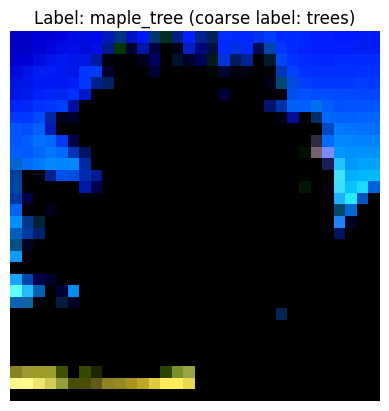

In [18]:
plt.imshow(img.permute(1, 2, 0))
plt.title(f"Label: {fine_classes[label]} (coarse label: {coarse_classes[coarse_label]})")
plt.axis('off')
plt.show()

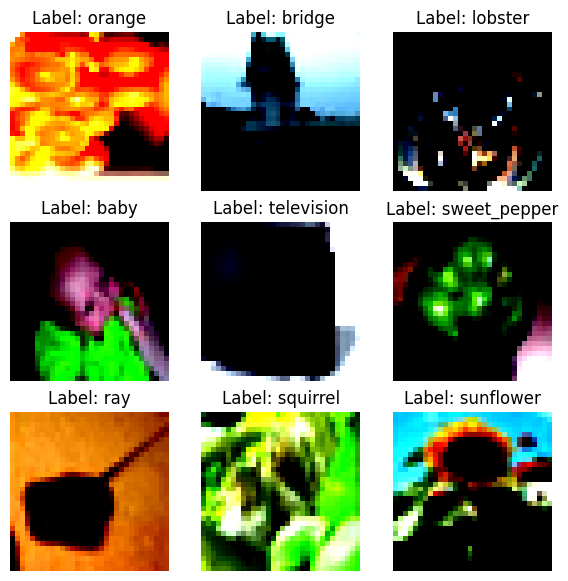

In [19]:
import torch
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(7, 7))
row, col = 3, 3
for i in range(1, row * col + 1):
  random_idx = torch.randint(0, len(train_dataset), size=[1]).item()
  sample = train_dataset[random_idx]
  img = sample['img']
  label = sample['label']

  fig.add_subplot(row, col, i)
  plt.imshow(img.permute(1, 2, 0))
  plt.title(f"Label: {fine_classes[label]}")
  plt.axis('off')
plt.show()

In [20]:
print(train_dataloader)
print(val_dataloader)
print(test_dataloader)

In [21]:
# Fetch a single batch dictionary from the DataLoader
batch = next(iter(train_dataloader))

# Extract images and labels using their dictionary keys
images = batch['img']
labels = batch['label']

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)

Images shape: torch.Size([64, 3, 32, 32])
Labels shape: torch.Size([64])


In [22]:
from torch import nn
class CIFAR100_model_0(nn.Module):
  def __init__(self , input_shape:int , hidden_units:int , output_shape:int):
    super().__init__()
    self.block1 = nn.Sequential(
        nn.Conv2d(in_channels=input_shape , out_channels=hidden_units , kernel_size=3 , stride=1 , padding=1),
        nn.ReLU(),
        nn.Conv2d(in_channels=hidden_units , out_channels=hidden_units , kernel_size=3 , stride=1 , padding=1),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2 , stride=2)
    )
    self.block2 = nn.Sequential(
        nn.Conv2d(in_channels=hidden_units , out_channels=hidden_units , kernel_size=3 , stride=1 , padding=1),
        nn.ReLU(),
        nn.Conv2d(in_channels=hidden_units , out_channels=hidden_units , kernel_size=3 , stride=1 , padding=1),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2 , stride=2)
    )
    self.block3 = nn.Sequential(
        nn.Conv2d(in_channels=hidden_units , out_channels=hidden_units , kernel_size=3 , stride=1 , padding=1),
        nn.ReLU(),
        nn.Conv2d(in_channels=hidden_units , out_channels=hidden_units , kernel_size=3 , stride=1 , padding=1),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2 , stride=2)
    )
    self.classifier = nn.Sequential(
        nn.Flatten(),
        nn.Linear(in_features=hidden_units * 4 * 4 , out_features=output_shape)
    )

  def forward(self, x):
    x = self.block1(x)
    x = self.block2(x)
    x = self.block3(x)
    x = self.classifier(x)
    return x

torch.manual_seed(42)
model_0 = CIFAR100_model_0(input_shape=3 , hidden_units=10 , output_shape=100)
model_0

CIFAR100_model_0(
  (block1): Sequential(
    (0): Conv2d(3, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (block2): Sequential(
    (0): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (block3): Sequential(
    (0): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=160

In [23]:
#Setting up loss_fn and optimizer

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params=model_0.parameters() , lr=0.001)


In [24]:
##Using a helper fucntion
import requests
from pathlib import Path

# Download helper functions from Learn PyTorch repo (if not already downloaded)
if Path("helper_functions.py").is_file():
  print("helper_functions.py already exists, skipping download")
else:
  print("Downloading helper_functions.py")
  # Note: you need the "raw" GitHub URL for this to work
  request = requests.get("https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/helper_functions.py")
  with open("helper_functions.py", "wb") as f:
    f.write(request.content)

In [25]:
# from tqdm.auto import tqdm
# from helper_functions import accuracy_fn
# from timeit import default_timer as timer

# model_0 = model_0.to(device)

# train_time_start_on_model_0 = timer()

# epochs = 15

# for epoch in tqdm(range(epochs)):
#   print(f"Epoch: {epoch+1}\n-----------")

#   train_loss = 0
#   model_0.train()

#   for batch_idx, batch in enumerate(train_dataloader):
#     # Extract images (X) and labels (y) from the batch dictionary and move to device
#     X, y = batch['img'].to(device), batch['label'].to(device)

#     y_pred = model_0(X)
#     loss = loss_fn(y_pred, y)
#     train_loss += loss.item()

#     optimizer.zero_grad()
#     loss.backward()
#     optimizer.step()

#     if batch_idx % 400 == 0:
#       print(f"Looked at {batch_idx * len(X):5d}/{len(train_dataloader.dataset):5d} samples")
#   train_loss /= len(train_dataloader)

#   test_loss, test_acc = 0, 0
#   model_0.eval()
#   with torch.inference_mode():
#     for batch in val_dataloader:
#       # Extract images (X) and labels (y) from the validation batch dictionary and move to device
#       X, y = batch['img'].to(device), batch['label'].to(device)
#       y_pred = model_0(X)
#       loss = loss_fn(y_pred, y)
#       test_loss += loss.item()
#       test_acc += accuracy_fn(y_true=y, y_pred=y_pred.argmax(dim=1))
#     test_loss /= len(val_dataloader)
#     test_acc /= len(val_dataloader)
#   print(f"Train loss: {train_loss:.5f} | Test loss: {test_loss:.5f} | Test acc: {test_acc:.2f}%")

# train_time_end_on_model_0 = timer()
# total_training_time = train_time_end_on_model_0 - train_time_start_on_model_0
# print(f"Total training time: {total_training_time:.3f} seconds")

In [26]:
# def eval(model: nn.Module, dataloader: DataLoader, loss_fn: nn.Module, accuracy_fn):
#   model.eval()
#   test_loss, test_acc = 0, 0
#   with torch.inference_mode():
#     for batch in dataloader:
#       # Extract images (X) and labels (y) from the batch dictionary and move to device
#       X, y = batch['img'].to(device), batch['label'].to(device)
#       y_pred = model(X)
#       test_loss += loss_fn(y_pred, y)
#       test_acc += accuracy_fn(y_true=y, y_pred=y_pred.argmax(dim=1))
#     test_loss /= len(dataloader)
#     test_acc /= len(dataloader)

#   # Removed .item() from test_acc since it is already a float
#   return {
#       "Model": model.__class__.__name__,
#       "Loss": test_loss.item(),
#       "Accuracy": test_acc
#   }

# eval(model=model_0, dataloader=val_dataloader, loss_fn=loss_fn, accuracy_fn=accuracy_fn)

In [27]:
##Using GeLU instead of ReLU

from torch import nn
class CIFAR100_model_1(nn.Module):
  def __init__(self , input_shape:int , hidden_units:int , output_shape:int):
    super().__init__()
    self.block1 = nn.Sequential(
        nn.Conv2d(in_channels=input_shape , out_channels=hidden_units , kernel_size=3 , stride=1 , padding=1),
        nn.GELU(),
        nn.Conv2d(in_channels=hidden_units , out_channels=hidden_units , kernel_size=3 , stride=1 , padding=1),
        nn.GELU(),
        nn.MaxPool2d(kernel_size=2 , stride=2)
    )
    self.block2 = nn.Sequential(
        nn.Conv2d(in_channels=hidden_units , out_channels=hidden_units , kernel_size=3 , stride=1 , padding=1),
        nn.GELU(),
        nn.Conv2d(in_channels=hidden_units , out_channels=hidden_units , kernel_size=3 , stride=1 , padding=1),
        nn.GELU(),
        nn.MaxPool2d(kernel_size=2 , stride=2)
    )
    self.block3 = nn.Sequential(
        nn.Conv2d(in_channels=hidden_units , out_channels=hidden_units , kernel_size=3 , stride=1 , padding=1),
        nn.GELU(),
        nn.Conv2d(in_channels=hidden_units , out_channels=hidden_units , kernel_size=3 , stride=1 , padding=1),
        nn.GELU(),
        nn.MaxPool2d(kernel_size=2 , stride=2)
    )
    self.classifier = nn.Sequential(
        nn.Flatten(),
        nn.Linear(in_features=hidden_units * 4 * 4 , out_features=output_shape)
    )

  def forward(self, x):
    x = self.block1(x)
    x = self.block2(x)
    x = self.block3(x)
    x = self.classifier(x)
    return x

torch.manual_seed(42)
model_1 = CIFAR100_model_1(input_shape=3 , hidden_units=10 , output_shape=100)
model_1

CIFAR100_model_1(
  (block1): Sequential(
    (0): Conv2d(3, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): GELU(approximate='none')
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): GELU(approximate='none')
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (block2): Sequential(
    (0): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): GELU(approximate='none')
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): GELU(approximate='none')
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (block3): Sequential(
    (0): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): GELU(approximate='none')
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): GELU(approximate='none')
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=Fals

In [28]:
# optimizer_1 = torch.optim.Adam(params=model_1.parameters() , lr=0.001)
# from tqdm.auto import tqdm
# from helper_functions import accuracy_fn
# from timeit import default_timer as timer

# model_1 = model_1.to(device)

# train_time_start_on_model_1 = timer()

# epochs = 15

# for epoch in tqdm(range(epochs)):
#   print(f"Epoch: {epoch+1}\n-----------")

#   train_loss = 0
#   model_1.train()

#   for batch_idx, batch in enumerate(train_dataloader):
#     # Extract images (X) and labels (y) from the batch dictionary and move to device
#     X, y = batch['img'].to(device), batch['label'].to(device)

#     y_pred = model_1(X)
#     loss = loss_fn(y_pred, y)
#     train_loss += loss.item()

#     optimizer_1.zero_grad()
#     loss.backward()
#     optimizer_1.step()

#     if batch_idx % 400 == 0:
#       print(f"Looked at {batch_idx * len(X):5d}/{len(train_dataloader.dataset):5d} samples")
#   train_loss /= len(train_dataloader)

#   test_loss, test_acc = 0, 0
#   model_1.eval()
#   with torch.inference_mode():
#     for batch in val_dataloader:
#       # Extract images (X) and labels (y) from the validation batch dictionary and move to device
#       X, y = batch['img'].to(device), batch['label'].to(device)
#       y_pred = model_1(X)
#       loss = loss_fn(y_pred, y)
#       test_loss += loss.item()
#       test_acc += accuracy_fn(y_true=y, y_pred=y_pred.argmax(dim=1))
#     test_loss /= len(val_dataloader)
#     test_acc /= len(val_dataloader)
#   print(f"Train loss: {train_loss:.5f} | Test loss: {test_loss:.5f} | Test acc: {test_acc:.2f}%")

# train_time_end_on_model_1 = timer()
# total_training_time = train_time_end_on_model_1 - train_time_start_on_model_1
# print(f"Total training time: {total_training_time:.3f} seconds")

In [29]:
# eval(model=model_1, dataloader=val_dataloader, loss_fn=loss_fn, accuracy_fn=accuracy_fn)

In [30]:
from helper_functions import accuracy_fn

##Using `batch normalization` , `dropout` and `lr_schedular`

In [31]:

from torch import nn
class CIFAR100_model_2(nn.Module):
  def __init__(self , input_shape:int , hidden_units:int , output_shape:int , dropout_rate : float=0.1):
    super().__init__()
    self.block1 = nn.Sequential(
        nn.Conv2d(in_channels=input_shape , out_channels=hidden_units , kernel_size=3 , stride=1 , padding=1),
        nn.GELU(),
        nn.BatchNorm2d(hidden_units),
        nn.Conv2d(in_channels=hidden_units , out_channels=hidden_units , kernel_size=3 , stride=1 , padding=1),
        nn.GELU(),
        nn.BatchNorm2d(hidden_units),
        nn.MaxPool2d(kernel_size=2 , stride=2),
        nn.Dropout(dropout_rate)
    )
    self.block2 = nn.Sequential(
        nn.Conv2d(in_channels=hidden_units , out_channels=hidden_units , kernel_size=3 , stride=1 , padding=1),
        nn.GELU(),
        nn.BatchNorm2d(hidden_units),
        nn.Conv2d(in_channels=hidden_units , out_channels=hidden_units , kernel_size=3 , stride=1 , padding=1),
        nn.GELU(),
        nn.BatchNorm2d(hidden_units),
        nn.MaxPool2d(kernel_size=2 , stride=2),
        nn.Dropout(dropout_rate)
    )
    self.block3 = nn.Sequential(
        nn.Conv2d(in_channels=hidden_units , out_channels=hidden_units , kernel_size=3 , stride=1 , padding=1),
        nn.GELU(),
        nn.BatchNorm2d(hidden_units),
        nn.Conv2d(in_channels=hidden_units , out_channels=hidden_units , kernel_size=3 , stride=1 , padding=1),
        nn.GELU(),
        nn.BatchNorm2d(hidden_units),
        nn.MaxPool2d(kernel_size=2 , stride=2),
        nn.Dropout(dropout_rate)
    )
    self.classifier = nn.Sequential(
        nn.Flatten(),
        nn.Linear(in_features=hidden_units * 4 * 4 , out_features=output_shape)
    )

  def forward(self, x):
    x = self.block1(x)
    x = self.block2(x)
    x = self.block3(x)
    x = self.classifier(x)
    return x

torch.manual_seed(42)
model_2 = CIFAR100_model_2(input_shape=3 , hidden_units=10 , output_shape=100).to(device)
model_2

CIFAR100_model_2(
  (block1): Sequential(
    (0): Conv2d(3, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): GELU(approximate='none')
    (2): BatchNorm2d(10, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (3): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): GELU(approximate='none')
    (5): BatchNorm2d(10, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (7): Dropout(p=0.1, inplace=False)
  )
  (block2): Sequential(
    (0): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): GELU(approximate='none')
    (2): BatchNorm2d(10, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (3): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): GELU(approximate='none')
    (5): BatchNorm2d(10, eps=1e-05, momentum=0.1, affine=True, bias=True

In [32]:
# optimizer_2 = torch.optim.Adam(params=model_2.parameters() , lr=0.001)
# scheduler_2 = torch.optim.lr_scheduler.CosineAnnealingLR(
#     optimizer_2,
#     T_max= epochs
# )

In [33]:
# from tqdm.auto import tqdm
# from helper_functions import accuracy_fn
# from timeit import default_timer as timer

# train_time_start_model_2 = timer()
# epochs = 20

# for epoch in tqdm(range(epochs)):
#     print(f"\nEpoch: {epoch + 1}/{epochs}")
#     print("-" * 30)

#     # Training Phase
#     train_loss = 0
#     model_2.train()

#     for batch_idx, batch in enumerate(train_dataloader):

#         X, y =batch['img'].to(device), batch['label'].to(device)

#         # Forward pass
#         y_pred = model_2(X)
#         loss = loss_fn(y_pred, y)
#         train_loss += loss.item()

#         # Backward pass
#         optimizer_2.zero_grad()
#         loss.backward()
#         optimizer_2.step()

#         if batch_idx % 400 == 0:
#             print(f"  Looked at {batch_idx * len(X):5d}/{len(train_dataloader.dataset):5d} samples")

#     train_loss /= len(train_dataloader)

#     # Step the learning rate scheduler at the end of the epoch
#     old_lr = optimizer_2.param_groups[0]['lr']
#     scheduler_2.step()
#     new_lr = optimizer_2.param_groups[0]['lr']
#     print(f"  [LR Scheduler] Learning rate adjusted from {old_lr:.6f} to {new_lr:.6f}")

#     # Testing Phase
#     test_loss, test_acc = 0, 0
#     model_2.eval()

#     with torch.inference_mode():
#         for batch in val_dataloader:
#             X, y = batch['img'].to(device), batch['label'].to(device)
#             y_pred = model_2(X)
#             test_loss += loss_fn(y_pred, y).item()
#             test_acc += accuracy_fn(y_true=y, y_pred=y_pred.argmax(dim=1))

#         test_loss /= len(val_dataloader)
#         test_acc /= len(val_dataloader)

#     print(f"  -> Train Loss: {train_loss:.4f} | Validation Loss: {test_loss:.4f} | Validation Accuracy: {test_acc:.2f}%")

# train_time_end_model_2 = timer()
# total_train_time_model_2 = train_time_end_model_2 - train_time_start_model_2
# print(f"\n[INFO] Total training time: {total_train_time_model_2:.3f} seconds")

In [34]:
# eval(model_2 , dataloader=val_dataloader , loss_fn=loss_fn , accuracy_fn=accuracy_fn)

## using Resnet

In [35]:
from torch import nn
from torchvision import models

In [36]:
class CIFAR100_ResNet18(nn.Module):
  def __init__(self, num_classes=100):
    super().__init__()

    self.resnet = models.resnet18(weights=None)

    self.resnet.conv1 = nn.Conv2d(in_channels=3, out_channels=64, kernel_size=3, stride=1, padding=1, bias=False)

    self.resnet.maxpool = nn.Identity()

    self.resnet.fc = nn.Linear(in_features=512, out_features=num_classes)

  def forward(self, x):
    return self.resnet(x)

# Instantiate and move to device
torch.manual_seed(42)
model_3 = CIFAR100_ResNet18(num_classes=100).to(device)
model_3

CIFAR100_ResNet18(
  (resnet): ResNet(
    (conv1): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (maxpool): Identity()
    (layer1): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      )
      (1): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=

In [37]:
# epochs = 20

# optimizer_3 = torch.optim.Adam(params=model_3.parameters(), lr=0.001)
# scheduler_3 = torch.optim.lr_scheduler.CosineAnnealingLR(
#     optimizer_3,
#     T_max=epochs
# )

In [38]:
# from tqdm.auto import tqdm
# from helper_functions import accuracy_fn
# from timeit import default_timer as timer

# train_time_start_model_3 = timer()
# epochs = 20

# for epoch in tqdm(range(epochs)):
#     print(f"\nEpoch: {epoch + 1}/{epochs}")
#     print("-" * 30)

#     # Training Phase
#     train_loss = 0
#     model_3.train()

#     for batch_idx, batch in enumerate(train_dataloader):

#         X, y =batch['img'].to(device), batch['label'].to(device)

#         # Forward pass
#         y_pred = model_3(X)
#         loss = loss_fn(y_pred, y)
#         train_loss += loss.item()

#         # Backward pass
#         optimizer_3.zero_grad()
#         loss.backward()
#         optimizer_3.step()

#         if batch_idx % 400 == 0:
#             print(f"  Looked at {batch_idx * len(X):5d}/{len(train_dataloader.dataset):5d} samples")

#     train_loss /= len(train_dataloader)

#     # Step the learning rate scheduler at the end of the epoch
#     old_lr = optimizer_3.param_groups[0]['lr']
#     scheduler_3.step()
#     new_lr = optimizer_3.param_groups[0]['lr']
#     print(f"  [LR Scheduler] Learning rate adjusted from {old_lr:.6f} to {new_lr:.6f}")

#     # Testing Phase
#     test_loss, test_acc = 0, 0
#     model_3.eval()

#     with torch.inference_mode():
#         for batch in val_dataloader:
#             X, y = batch['img'].to(device), batch['label'].to(device)
#             y_pred = model_3(X)
#             test_loss += loss_fn(y_pred, y).item()
#             test_acc += accuracy_fn(y_true=y, y_pred=y_pred.argmax(dim=1))

#         test_loss /= len(val_dataloader)
#         test_acc /= len(val_dataloader)

#     print(f"  -> Train Loss: {train_loss:.4f} | Validation Loss: {test_loss:.4f} | Validation Accuracy: {test_acc:.2f}%")

# train_time_end_model_3 = timer()
# total_train_time_model_3 = train_time_end_model_3 - train_time_start_model_3
# print(f"\n[INFO] Total training time: {total_train_time_model_3:.3f} seconds")

In [39]:
# def eval_model(model: torch.nn.Module, dataloader: torch.utils.data.DataLoader, loss_fn: torch.nn.Module, accuracy_fn):
#     model.eval()
#     test_loss, test_acc = 0, 0
#     with torch.inference_mode():
#         for batch in dataloader:
#             X, y = batch['img'].to(device), batch['label'].to(device)
#             y_pred = model(X)
#             test_loss += loss_fn(y_pred, y)
#             test_acc += accuracy_fn(y_true=y, y_pred=y_pred.argmax(dim=1))
#         test_loss /= len(dataloader)
#         test_acc /= len(dataloader)

#     return {
#         "Model": model.__class__.__name__,
#         "Loss": test_loss.item(),
#         "Accuracy": test_acc
#     }

# eval_model(model=model_3, dataloader=val_dataloader, loss_fn=loss_fn, accuracy_fn=accuracy_fn)

### 1. Introduce Strong Data Augmentation for Training
We apply `RandomCrop` (with padding to preserve edge details) and `RandomHorizontalFlip` to the training set to prevent the ResNet model from memorizing the images.

In [40]:
from torchvision import transforms
from torch.utils.data import DataLoader

# Augmentation for training
train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean=(0.5071, 0.4867, 0.4408),
                         std=(0.2675, 0.2565, 0.2761))
])

# Only normalization for validation/testing
eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=(0.5071, 0.4867, 0.4408),
                         std=(0.2675, 0.2565, 0.2761))
])

# Define the batch transformation mapping functions
def transform_train_batch(batch):
    batch['img'] = [train_transform(img) for img in batch['img']]
    batch['label'] = batch['fine_label']
    return batch

def transform_eval_batch(batch):
    batch['img'] = [eval_transform(img) for img in batch['img']]
    batch['label'] = batch['fine_label']
    return batch

# Apply transformations to the split dataset
augmented_train_dataset = split_result['train'].with_transform(transform_train_batch)
augmented_val_dataset = split_result['test'].with_transform(transform_eval_batch)

# Create new DataLoaders
augmented_train_dataloader = DataLoader(
    augmented_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2
)

augmented_val_dataloader = DataLoader(
    augmented_val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

### 2. Re-Train ResNet-18 with Augmented Data
Now we re-instantiate our model to reset the weights, and train it again with the augmented dataloader.

In [41]:
# # Re-instantiate to reset weights
# torch.manual_seed(42)
# model_3_augmented = CIFAR100_ResNet18(num_classes=100).to(device)

# optimizer_3_aug = torch.optim.Adam(params=model_3_augmented.parameters(), lr=0.001)
# scheduler_3_aug = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer_3_aug, T_max=20)

# epochs = 20
# train_time_start = timer()

# for epoch in range(epochs):
#     print(f"\nEpoch: {epoch + 1}/{epochs}")
#     print("-" * 30)

#     # Training Phase
#     train_loss = 0
#     model_3_augmented.train()

#     for batch_idx, batch in enumerate(augmented_train_dataloader):
#         X, y = batch['img'].to(device), batch['label'].to(device)

#         y_pred = model_3_augmented(X)
#         loss = loss_fn(y_pred, y)
#         train_loss += loss.item()

#         optimizer_3_aug.zero_grad()
#         loss.backward()
#         optimizer_3_aug.step()

#     train_loss /= len(augmented_train_dataloader)
#     scheduler_3_aug.step()

#     # Validation Phase
#     test_loss, test_acc = 0, 0
#     model_3_augmented.eval()

#     with torch.inference_mode():
#         for batch in augmented_val_dataloader:
#             X, y = batch['img'].to(device), batch['label'].to(device)
#             y_pred = model_3_augmented(X)
#             test_loss += loss_fn(y_pred, y).item()
#             test_acc += accuracy_fn(y_true=y, y_pred=y_pred.argmax(dim=1))

#         test_loss /= len(augmented_val_dataloader)
#         test_acc /= len(augmented_val_dataloader)

#     print(f"  -> Train Loss: {train_loss:.4f} | Validation Loss: {test_loss:.4f} | Validation Accuracy: {test_acc:.2f}%")

# train_time_end = timer()
# print(f"\n[INFO] Finished training in {(train_time_end - train_time_start):.3f} seconds")

### 3. Implement Transfer Learning with Pre-trained ResNet-18
Instead of training from scratch, we load the pre-trained weights from ImageNet (`weights=models.ResNet18_Weights.DEFAULT`), adapt the input and output layers, and train/fine-tune it.

In [42]:
class CIFAR100_PretrainedResNet18(nn.Module):
  def __init__(self, num_classes=100):
    super().__init__()
    # Load ResNet-18 with pre-trained weights
    self.resnet = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

    # Adapt first layer to handle 32x32 dimensions better
    self.resnet.conv1 = nn.Conv2d(in_channels=3, out_channels=64, kernel_size=3, stride=1, padding=1, bias=False)
    self.resnet.maxpool = nn.Identity()

    # Adapt final fully connected classifier
    self.resnet.fc = nn.Linear(in_features=512, out_features=num_classes)

  def forward(self, x):
    return self.resnet(x)

# Instantiate the model
torch.manual_seed(42)
model_4 = CIFAR100_PretrainedResNet18(num_classes=100).to(device)
model_4

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 185MB/s]


CIFAR100_PretrainedResNet18(
  (resnet): ResNet(
    (conv1): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (maxpool): Identity()
    (layer1): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      )
      (1): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_runn

### 4. Fine-Tune Pre-trained ResNet-18
We use a slightly lower initial learning rate (`0.0005` instead of `0.001`) since the weights are already high quality, to avoid disrupting the pre-trained features.

In [43]:
# optimizer_pretrained = torch.optim.Adam(params=model_4.parameters(), lr=0.0005)
# scheduler_pretrained = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer_pretrained, T_max=epochs)

# epochs = 15
# train_time_start = timer()

# for epoch in range(epochs):
#     print(f"\nEpoch: {epoch + 1}/{epochs}")
#     print("-" * 30)

#     # Training
#     train_loss = 0
#     model_4.train()
#     for batch_idx, batch in enumerate(augmented_train_dataloader):
#         X, y = batch['img'].to(device), batch['label'].to(device)

#         y_pred = model_4(X)
#         loss = loss_fn(y_pred, y)
#         train_loss += loss.item()

#         optimizer_pretrained.zero_grad()
#         loss.backward()
#         optimizer_pretrained.step()

#     train_loss /= len(augmented_train_dataloader)
#     scheduler_pretrained.step()

#     # Validation
#     test_loss, test_acc = 0, 0
#     model_4.eval()
#     with torch.inference_mode():
#         for batch in augmented_val_dataloader:
#             X, y = batch['img'].to(device), batch['label'].to(device)
#             y_pred = model_4(X)
#             test_loss += loss_fn(y_pred, y).item()
#             test_acc += accuracy_fn(y_true=y, y_pred=y_pred.argmax(dim=1))

#         test_loss /= len(augmented_val_dataloader)
#         test_acc /= len(augmented_val_dataloader)

#     print(f"  -> Train Loss: {train_loss:.4f} | Validation Loss: {test_loss:.4f} | Validation Accuracy: {test_acc:.2f}%")

# train_time_end = timer()
# print(f"\n[INFO] Finished training in {(train_time_end - train_time_start):.3f} seconds")

In [44]:
# eval_model(model=model_4 , dataloader=val_dataloader , loss_fn=loss_fn , accuracy_fn=accuracy_fn)

### 1. High-Resolution Transforms with Advanced Augmentation
We will resize the CIFAR-100 images from $32 \times 32$ to $224 \times 224$ (the native resolution of pre-trained ImageNet models) and keep our horizontal flips and random crops for strong regularization.

In [45]:
from torchvision import transforms
from torch.utils.data import DataLoader

# Advanced high-resolution transforms
high_res_train_transform = transforms.Compose([
    transforms.Resize(224, interpolation=transforms.InterpolationMode.BILINEAR),
    transforms.RandomCrop(224, padding=28),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean=(0.5071, 0.4867, 0.4408),
                         std=(0.2675, 0.2565, 0.2761))
])

high_res_eval_transform = transforms.Compose([
    transforms.Resize(224, interpolation=transforms.InterpolationMode.BILINEAR),
    transforms.ToTensor(),
    transforms.Normalize(mean=(0.5071, 0.4867, 0.4408),
                         std=(0.2675, 0.2565, 0.2761))
])

def transform_high_res_train_batch(batch):
    batch['img'] = [high_res_train_transform(img) for img in batch['img']]
    batch['label'] = batch['fine_label']
    return batch

def transform_high_res_eval_batch(batch):
    batch['img'] = [high_res_eval_transform(img) for img in batch['img']]
    batch['label'] = batch['fine_label']
    return batch

# Re-apply dataset maps
high_res_train_dataset = split_result['train'].with_transform(transform_high_res_train_batch)
high_res_val_dataset = split_result['test'].with_transform(transform_high_res_eval_batch)

# High-resolution dataloaders (using smaller batch size 32 to avoid GPU Out-Of-Memory)
high_res_train_dataloader = DataLoader(high_res_train_dataset, batch_size=32, shuffle=True, num_workers=2)
high_res_val_dataloader = DataLoader(high_res_val_dataset, batch_size=32, shuffle=False, num_workers=2)

### 2. Instantiate Pre-trained ResNet-50
We load a pre-trained **ResNet-50** backbone and replace its classification head to output predictions for the 100 CIFAR classes.

In [46]:
from torchvision import models
import torch.nn as nn

class CIFAR100_PretrainedResNet50(nn.Module):
    def __init__(self, num_classes=100):
        super().__init__()
        self.resnet = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)

        # Replace final fully connected classifier
        self.resnet.fc = nn.Linear(in_features=2048, out_features=num_classes)

    def forward(self, x):
        return self.resnet(x)

torch.manual_seed(42)
model_5 = CIFAR100_PretrainedResNet50(num_classes=100).to(device)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 137MB/s]


### 3. Fine-Tuning with Label Smoothing Cross Entropy Loss
We train the model using `label_smoothing=0.1` inside the CrossEntropyLoss function to prevent overconfident predictions.

In [47]:
from timeit import default_timer as timer

# Configure label smoothing loss
loss_fn_smooth = nn.CrossEntropyLoss(label_smoothing=0.1)

optimizer_5 = torch.optim.Adam(params=model_5.parameters(), lr=0.0003)
scheduler_5 = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer_5, T_max=10)

epochs = 10
train_time_start = timer()

for epoch in range(epochs):
    print(f"\nEpoch: {epoch + 1}/{epochs}")
    print("-" * 30)

    # Training
    train_loss = 0
    model_5.train()
    for batch in high_res_train_dataloader:
        X, y = batch['img'].to(device), batch['label'].to(device)

        y_pred = model_5(X)
        loss = loss_fn_smooth(y_pred, y)
        train_loss += loss.item()

        optimizer_5.zero_grad()
        loss.backward()
        optimizer_5.step()

    train_loss /= len(high_res_train_dataloader)
    scheduler_5.step()

    # Validation
    val_loss, val_acc = 0, 0
    model_5.eval()
    with torch.inference_mode():
        for batch in high_res_val_dataloader:
            X, y = batch['img'].to(device), batch['label'].to(device)
            y_pred = model_5(X)
            val_loss += loss_fn_smooth(y_pred, y).item()
            val_acc += accuracy_fn(y_true=y, y_pred=y_pred.argmax(dim=1))

        val_loss /= len(high_res_val_dataloader)
        val_acc /= len(high_res_val_dataloader)

    print(f"  -> Train Loss: {train_loss:.4f} | Validation Loss: {val_loss:.4f} | Validation Accuracy: {val_acc:.2f}%")

train_time_end = timer()
print(f"\n[INFO] High-resolution training finished in {(train_time_end - train_time_start):.3f} seconds")


Epoch: 1/10
------------------------------
  -> Train Loss: 2.0378 | Validation Loss: 1.6679 | Validation Accuracy: 71.62%

Epoch: 2/10
------------------------------
  -> Train Loss: 1.5369 | Validation Loss: 1.5639 | Validation Accuracy: 75.30%

Epoch: 3/10
------------------------------
  -> Train Loss: 1.3624 | Validation Loss: 1.4688 | Validation Accuracy: 78.16%

Epoch: 4/10
------------------------------
  -> Train Loss: 1.2225 | Validation Loss: 1.4736 | Validation Accuracy: 78.05%

Epoch: 5/10
------------------------------
  -> Train Loss: 1.1024 | Validation Loss: 1.3672 | Validation Accuracy: 81.13%

Epoch: 6/10
------------------------------
  -> Train Loss: 0.9999 | Validation Loss: 1.3629 | Validation Accuracy: 82.15%

Epoch: 7/10
------------------------------
  -> Train Loss: 0.9240 | Validation Loss: 1.3373 | Validation Accuracy: 82.62%

Epoch: 8/10
------------------------------
  -> Train Loss: 0.8751 | Validation Loss: 1.3030 | Validation Accuracy: 83.62%

Epoch: 

In [51]:
from sklearn.metrics import confusion_matrix, recall_score, precision_score, f1_score, classification_report

# Convert GPU tensors to CPU numpy arrays and get the class predictions
y_true_numpy = y.cpu().numpy()
y_pred_numpy = y_pred.argmax(dim=1).cpu().numpy()

print(f"Confusion matrix :\n{confusion_matrix(y_true_numpy, y_pred_numpy)}")
print(f"Recall (macro) :{recall_score(y_true_numpy, y_pred_numpy, average='macro')}")
print(f"Precision (macro) :{precision_score(y_true_numpy, y_pred_numpy, average='macro')}")
print(f"F1 score (macro) :{f1_score(y_true_numpy, y_pred_numpy, average='macro')}")
print(f"Classification report :\n{classification_report(y_true_numpy, y_pred_numpy)}")

Confusion matrix :
[[0 0 0 0 0 0 0 0 1]
 [0 1 0 0 0 0 0 0 0]
 [0 0 1 0 0 0 0 0 0]
 [0 0 0 1 0 0 0 0 0]
 [0 0 0 0 1 0 0 0 0]
 [0 0 0 0 0 1 0 0 0]
 [0 0 0 0 0 0 1 0 0]
 [0 0 0 0 0 0 0 1 0]
 [0 0 0 0 0 0 0 0 0]]
Recall (macro) :0.7777777777777778
Precision (macro) :0.7777777777777778
F1 score (macro) :0.7777777777777778
Classification report :
              precision    recall  f1-score   support

          35       0.00      0.00      0.00         1
          46       1.00      1.00      1.00         1
          52       1.00      1.00      1.00         1
          57       1.00      1.00      1.00         1
          58       1.00      1.00      1.00         1
          62       1.00      1.00      1.00         1
          77       1.00      1.00      1.00         1
          88       1.00      1.00      1.00         1
          98       0.00      0.00      0.00         0

    accuracy                           0.88         8
   macro avg       0.78      0.78      0.78         8
weighte

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_

In [52]:
import os
import torch

# Create a directory for saving models if it doesn't exist
os.makedirs('/content/models', exist_ok=True)

# Save the model state dictionary
save_path = '/content/models/cifar100_resnet50.pth'
torch.save(model_5.state_dict(), save_path)
print(f"Model successfully saved to {save_path}")

Model successfully saved to /content/models/cifar100_resnet50.pth
